# Analyze grayvalue dynamics in membrane

Goal: obtain water content and profile

In [1]:
import json
import os
import socket
host = socket.gethostname()   
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array
from matplotlib import cm
from matplotlib.colors import Normalize

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'

elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path_abs = os.path.join(toppath,'processing', '02_abs_registered_3p1D')
registered_path = os.path.join(toppathSSD, '02_registered_3p1D')

px = 2.75e-6
vx = px**3

# fetch githash
import subprocess
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=14)

In [3]:
import pickle

In [4]:
charge_dict_path = os.path.join(toppath, 'processing', 'charge_dict.p')

In [5]:
charge_dict = pickle.load(open(charge_dict_path, 'rb'))

## Experiment with data

In [6]:
sample = '4'
segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
seg_data = xr.load_dataset(segpath)

In [7]:
regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
regpath = os.path.join(registered_path_abs, '02_'+sample+'_abs_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)
[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
images = [im for im in reg_data.keys() if im[3:7] == 'imag']
images.sort()

In [8]:
t_utc_tomo = reg_data['t_utc'].data

In [9]:
a,b,c,d,e,f = seg_data.attrs['cropping of seg data']

In [10]:
seg_data.attrs['cropping of seg data']

array([ 10, -10,  10, -10,  10, -10])

In [11]:
shp = reg_data[images[4]][ar:br, cr:dr, er:fr][a:b,c:d,e:f].shape
# shp = data[images[4]][:, c:d, e:f].shape
shp = shp + (len(images),)

In [12]:
im = np.zeros(shp, dtype = np.uint16)

In [13]:
# with obtained cropping data
for i in range(shp[-1]):
    if i%10 == 0:
        print(i)
    im[...,i] = reg_data[images[i]][ar:br, cr:dr, er:fr][a:b, c:d, e:f].data
    # im[...,i] = data[images[i]][:, c:d, e:f].data

0
10
20
30
40
50
60
70


In [26]:
reg_data.close()

In [27]:
# im_phase = im.copy()
# im_abs = im

In [14]:
im.shape

(761, 78, 1526, 71)

In [15]:
membrane = seg_data['segmented'][a:b,c:d,e:f]==0 #correction for 4 , check if match

In [16]:
membrane.shape

(781, 88, 1526, 71)

In [30]:
cmap = cm.inferno

In [31]:
test = np.ones(membrane.shape, dtype=np.float16)

In [32]:
test[~membrane] = np.nan

In [33]:
im_phase = im_phase*test
im_abs = im_abs*test

In [17]:
 seg_data

<xarray.Dataset>
Dimensions:         (x: 801, y: 108, z: 1546, timestep: 71, feature: 110,
                     x1: 781, y1: 88, z1: 1526)
Coordinates:
  * x               (x) int64 0 1 2 3 4 5 6 7 ... 794 795 796 797 798 799 800
  * y               (y) int64 0 1 2 3 4 5 6 7 ... 101 102 103 104 105 106 107
  * z               (z) int64 0 1 2 3 4 5 6 ... 1540 1541 1542 1543 1544 1545
  * timestep        (timestep) int64 0 1 2 3 4 5 6 7 ... 63 64 65 66 67 68 69 70
  * feature         (feature) object 'diff_to_first_' ... 'full_temp_min_Gaus...
  * x1              (x1) int64 0 1 2 3 4 5 6 7 ... 774 775 776 777 778 779 780
  * y1              (y1) int64 0 1 2 3 4 5 6 7 8 ... 79 80 81 82 83 84 85 86 87
  * z1              (z1) int64 0 1 2 3 4 5 6 ... 1520 1521 1522 1523 1524 1525
Data variables:
    segmented       (x, y, z, timestep) uint8 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1
    t_utc           (timestep) float64 1.667e+09 1.667e+09 ... 1.667e+09
    time            (timestep) float64 5.04 15.94 75.97 ... 427.8 487.8 547.8
    gas_phases      (x1, y1, z1, timestep) uint8 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0
    membrane_mask   (x1, y1, z1, timestep) uint8 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0
    BPM_cav_volume  (timestep) float64 3.377e+04 2.781e+04 ... 3.936e+04
    CL_cav_volume   (timestep) float64 1.085e+04 9.77e+03 ... 5.408e+04
Attributes: (12/23)
    name:                                              4
    voxel size:                                        2.75 um
    voxel:                                             2.75e-06
    post rotation cropping coordinates [a:b,c:d,e:f]:  [  30  851   70  768  ...
    rotation angle 1:                                  -4.5
    rotation angle 2:                                  -4.5
    ...                                                ...
    05_ML_cropping:                                    [  10  -10  310 -280  ...
    pytrain_git:                                       8c6e0dd
    05_coely_gitsha:                                   3c86993
    comment:                                           gas phases: 1 in gas p...
    gas label gitsha:                                  2ceab9f
    cropping of seg data:                              [ 10 -10  10 -10  10 -10]

In [34]:
ph_min = -1e-5
ph_max = 5e-5
abs_min = -1e-3
abs_max = 1.5e3

In [62]:
delta = 0.35e-7
beta = 1e-9

In [64]:
delta/beta

35.0

In [41]:
def conversion(valint, tmin, tmax):
    b16 = 2**16-1
    m = b16/(tmax-tmin)
    valfloat = tmin + valint/m
    return valfloat

In [39]:
mean_grays = np.nanmean(im_phase, axis = (0,1,2))
mean_grays_abs = np.nanmean(im_abs, axis = (0,1,2))

In [52]:
mean_grays_float = conversion(mean_grays, ph_min, ph_max)
mean_grays_abs_float = conversion(mean_grays_abs, ph_min, ph_max)

In [44]:
# med_grays = np.nanmedian(im, axis = (0,1,2))

In [45]:
# std_grays = np.nanstd(im, axis = (0,1,2))

In [44]:
HFR_time = charge_dict[sample]['HFR']['HFRtime']
HFR = charge_dict[sample]['HFR']['fit_HFR']
HFR0 = charge_dict[sample]['HFR']['highfreqR']
t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
sat = charge_dict[sample]['saturation']
TH = charge_dict[sample]['TH']
crack_vol =charge_dict[sample]['crack volume']
memvol = charge_dict[sample]['membrane volume']
rel_swell = memvol/memvol.min()*100
Q = charge_dict[sample]['Q']
I = -charge_dict[sample]['I']
E = -charge_dict[sample]['E']
time = charge_dict[sample]['time']

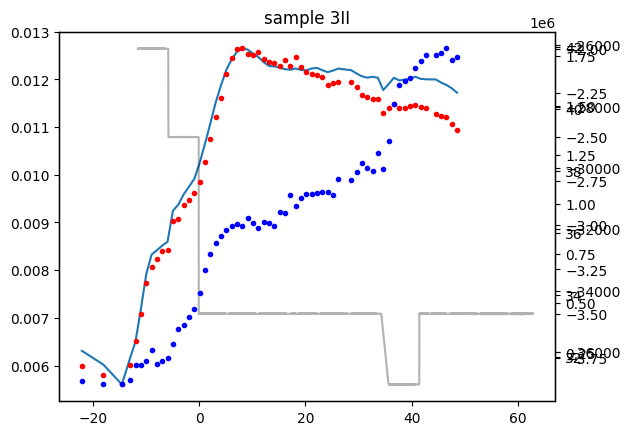

In [50]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.00525,0.013)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
# ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
# ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

# ax6 = ax.twinx()
# ax6.plot(t_tomo/60 - 11.5, memvol, 'g.')

In [52]:
# mean_grays_abs = mean_grays.copy()

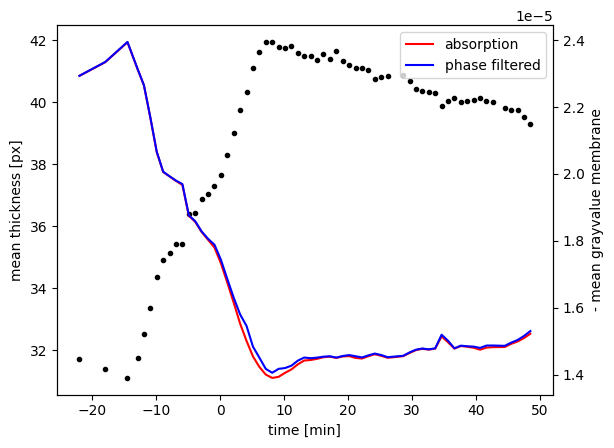

In [89]:
fig, ax = plt.subplots()
ax.plot(t_tomo/60 - 11.5, TH, 'k.')
ax.set_xlabel('time [min]')
ax.set_ylabel('mean thickness [px]')
ax2=ax.twinx()
# ax3=ax.twinx()
ax2.plot(t_tomo/60 - 11.5, mean_grays_abs_float,'r', label='absorption')
ax2.plot(t_tomo/60 - 11.5, mean_grays_float*4+3e-5,'b', label='phase filtered')
ax2.set_ylabel('- mean grayvalue membrane')
ax2.legend()
# ax3.legend(loc = 'upper left')

In [106]:
ts = 20
hist_abs = np.histogram(im_abs[...,ts], bins = 5000, range = (0,2**16), density=True)

In [117]:
hist_phase = np.histogram(im_phase[...,ts], bins = np.arange(5000,25000))

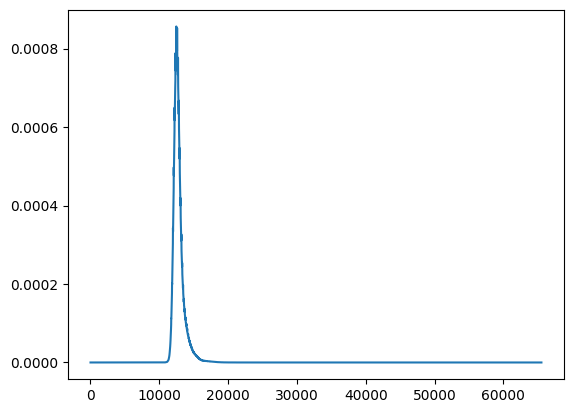

In [108]:
plt.plot(hist_phase[1][1:], hist_phase[0])

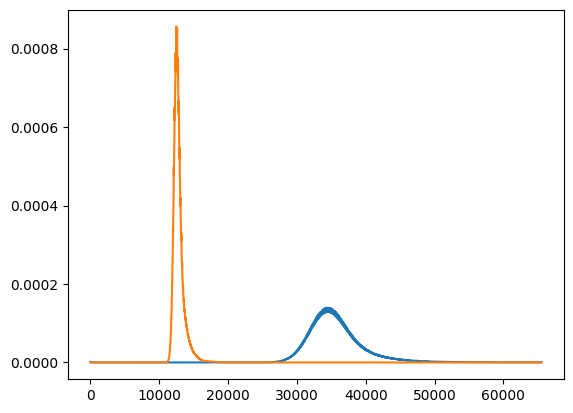

In [114]:
plt.plot(hist_abs[1][1:], hist_abs[0])
plt.plot(hist_phase[1][1:], hist_phase[0])

In [ ]:
*4-3.5

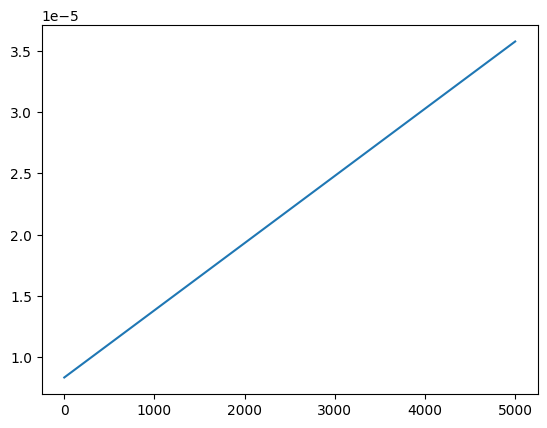

In [76]:
plt.plot(conversion(hist_abs[1][1:], ph_min, ph_max))

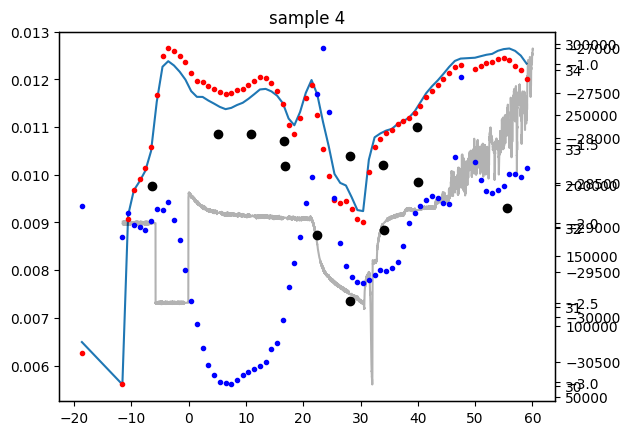

In [50]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.00525,0.013)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
# ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
# ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

# ax6 = ax.twinx()
# ax6.plot(t_tomo/60 - 11.5, memvol, 'g.')

Text(0.5, 1.0, 'sample 4')

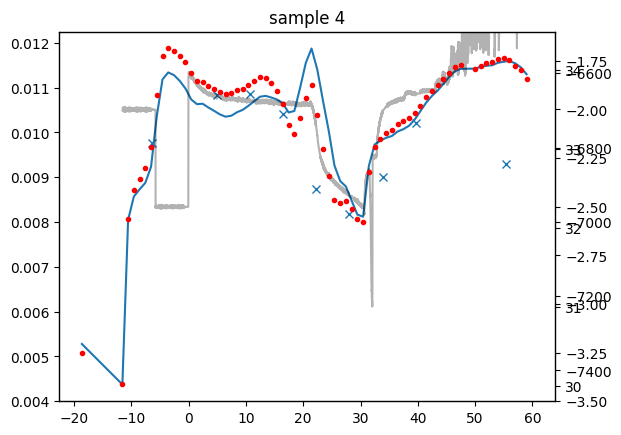

In [79]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.004,0.01225)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
ax3.set_ylim(-3.5,-1.6)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

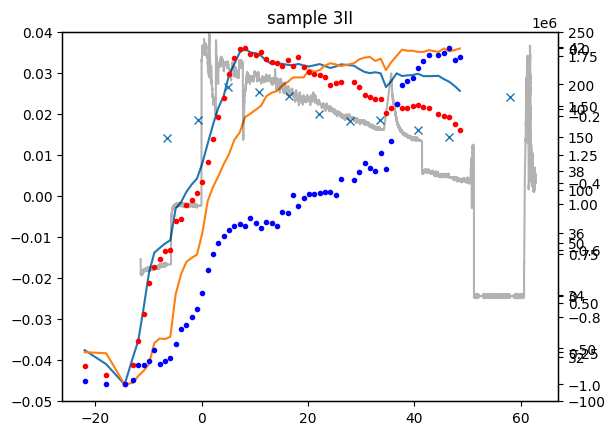

In [49]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(-0.05,0.04)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

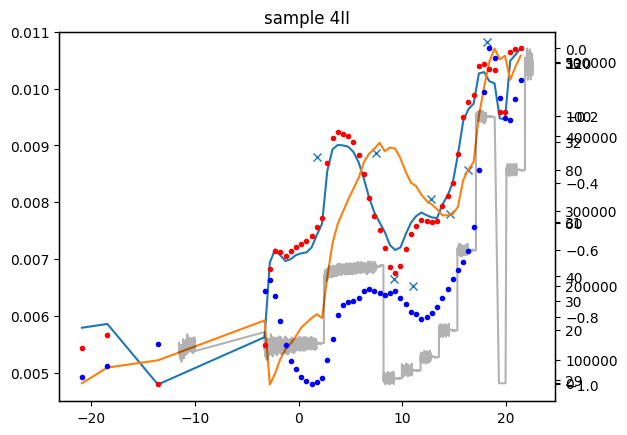

In [34]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.0045,0.011)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

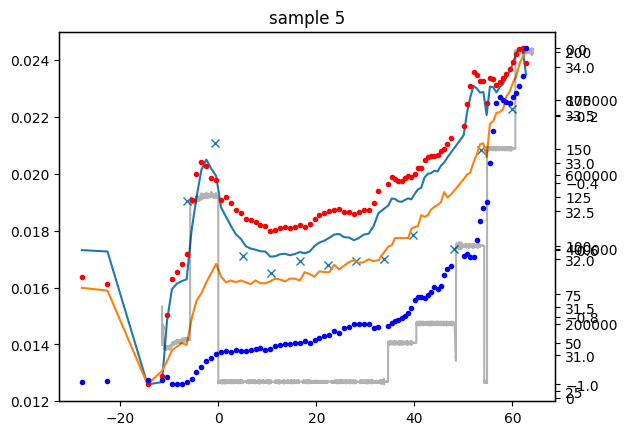

In [36]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

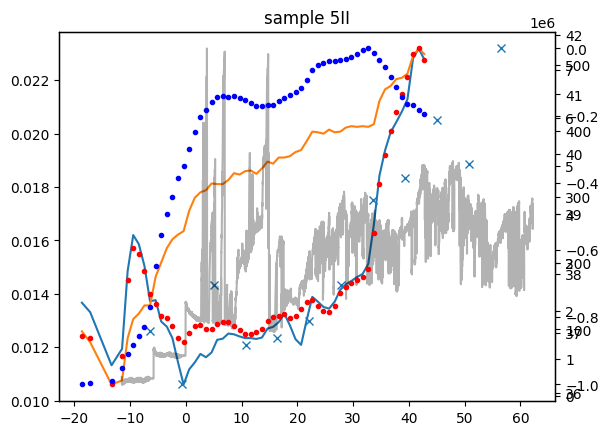

In [28]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))

# gray mean and thickness are basically the same because paginin filtering considers the propagation distance --> wider objects of same density are darker --> profiles useless, but gray value gives thickness
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

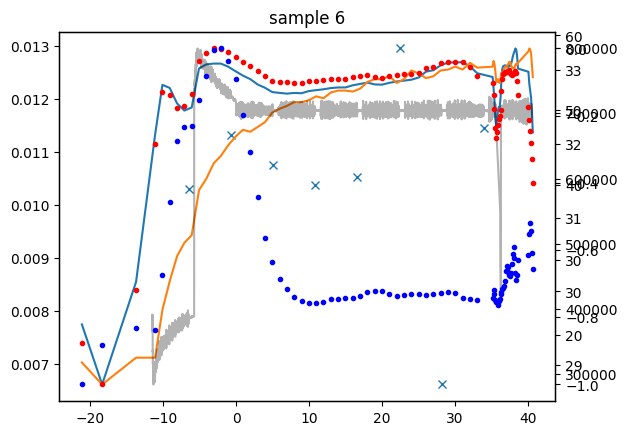

In [27]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'x')
# ax.set_ylim(0.012,0.025)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, I/0.1, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

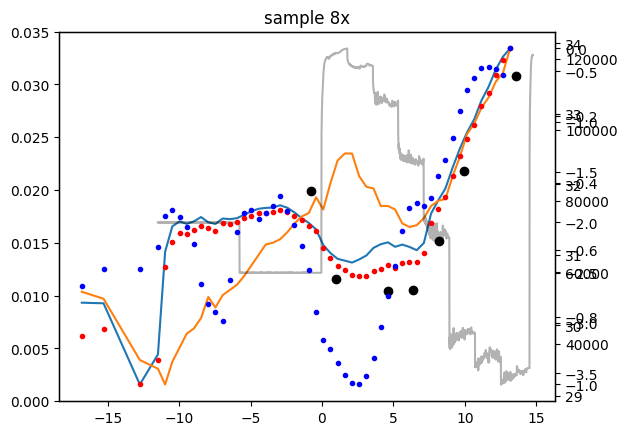

In [37]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.000,0.035)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

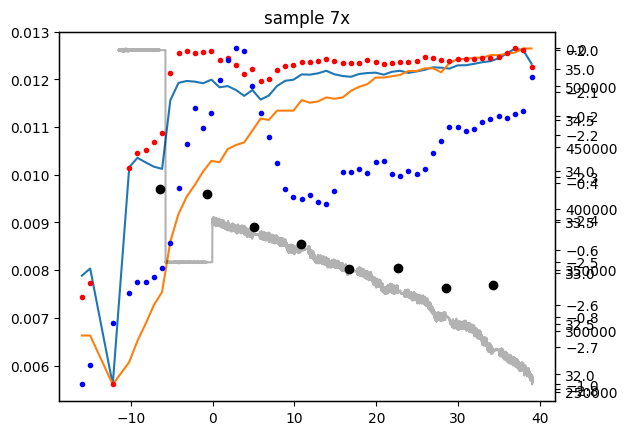

In [34]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, 'ko')
ax.set_ylim(0.00525,0.013)
ax2 = ax.twinx()
# ax2.plot(t_tomo/60 - 11.5, -mean_grays)  #std gray also depends on membrane thickness -> pretty logical, but no physical meaning, just noise ?!
ax2.plot(t_tomo/60 - 11.5,-(mean_grays-mean_grays.min())/(mean_grays.max()-mean_grays.min()))
ax2.plot(t_tomo/60 - 11.5,-(med_grays-med_grays.min())/(med_grays.max()-med_grays.min()))
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.3)
# ax3.set_ylim(-100,250)
ax4 = ax.twinx()
ax4.plot(t_tomo/60 - 11.5, TH, 'r.')
plt.title('sample '+sample)

ax5 = ax.twinx()
ax5.plot(t_tomo/60 - 11.5, crack_vol, 'b.')

## grayvalue statisitics for all samples

In [19]:
def gray_stats(sample):
    print(sample)
    segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
    seg_data = xr.load_dataset(segpath)
    
    regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
    reg_data = xr.open_dataset(regpath)
    [ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
    images = [im for im in reg_data.keys() if im[3:7] == 'imag']
    images.sort()

    a,b,c,d,e,f = seg_data.attrs['cropping of seg data']

    shp = reg_data[images[4]][ar:br, cr:dr, er:fr][a:b,c:d,e:f].shape
    # shp = data[images[4]][:, c:d, e:f].shape
    shp = shp + (len(images),)

    im = np.zeros(shp, dtype = np.uint16)

    # with obtained cropping data
    for i in range(shp[-1]):
        if i%10 == 0:
            print(i)
        im[...,i] = reg_data[images[i]][ar:br, cr:dr, er:fr][a:b, c:d, e:f].data
        # im[...,i] = data[images[i]][:, c:d, e:f].data
    t_utc_tomo = reg_data['t_utc'].data
    reg_data.close()

    if sample == '4':
        membrane = seg_data['segmented'][a:b,c:d,e:f,:]==0 #correction for 4 , check if match
    else:
        membrane = seg_data['segmented'][a:b,c:d,e:f,:]==0 #correction for 4 , check if match

    test = np.ones(membrane.shape, dtype=np.float16)
    test[~membrane] = np.nan
    im = im*test

    mean_grays = np.nanmean(im, axis = (0,1,2))
    med_grays = np.nanmedian(im, axis = (0,1,2))
    std_grays = np.nanstd(im, axis = (0,1,2))

    bins = np.arange(5000,25000)
    hists = np.zeros((len(mean_grays),len(bins)-1), dtype=np.uint32)

    for ts in range(len(mean_grays)):
        hist = np.histogram(im[...,ts], bins=bins)
        hists[ts,:] = hist[0]

    return mean_grays, med_grays, std_grays, hists, bins, t_utc_tomo

In [20]:
# grayval_dict = {}

In [21]:
samples = ['4', '3II', '3III', '4II', '5II', '5', '6', '7x', '8x', '1']

for sample in samples:
    mean_grays, med_grays, std_grays, hists, bins, t_utc_tomo = gray_stats(sample)
    grayval_dict[sample] = {'mean_grays': mean_grays, 'med_grays': med_grays, 'std_grays': std_grays, 'hists': hists, 'bins':bins, 't_utc_tomo': t_utc_tomo}

4
0
10
20
30
40
50
60
70
3II
0
10
20
30
40
50
60
3III
0
10
20
30
40
50
60
4II
0
10
20
30
40
50
5II
0
10
20
30
40
50
5
0
10
20
30
40
50
60
70
80
6
0
10
20
30
40
50
60
70
80
7x
0
10
20
30
40
50
8x
0
10
20
30
40
50
1
0
10
20
30


In [22]:
gray_dict_path = os.path.join(toppath, 'processing', 'gray_val_stats.p')

In [25]:
pickle.dump(grayval_dict, open(gray_dict_path, 'wb'))

In [13]:
import ctypes
def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

In [14]:
trim_memory()

1

In [17]:
sample

'4'